# W08A Ordinary least squares fitting

In [6]:
import numpy as np
import matplotlib.pyplot as plt

### Task 1

Sample a quadratic function:

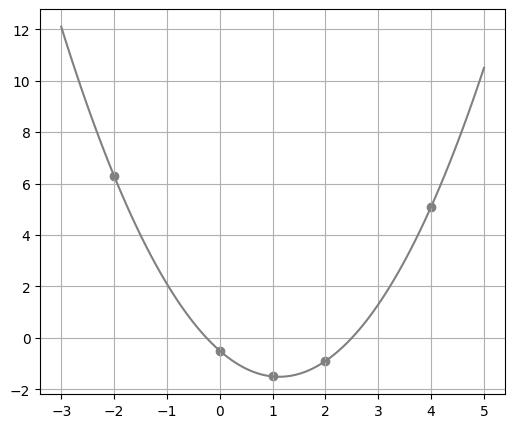

In [7]:
def func(x):
    return 4/5*(x+1/4)*(x-5/2)

xs = np.array([-2, 0, 1, 2, 4])
ys = func(xs)

x_lin = np.linspace(-3,5,100)
y_lin = func(x_lin)

fig, ax = plt.subplots(1,1,figsize=(6,5))
ax.scatter(xs, ys, c='grey')
ax.plot(x_lin, y_lin, c='grey')
ax.grid()

[[ 1. -2.  4.]
 [ 1.  0.  0.]
 [ 1.  1.  1.]
 [ 1.  2.  4.]
 [ 1.  4. 16.]]
[-0.5 -1.8  0.8]


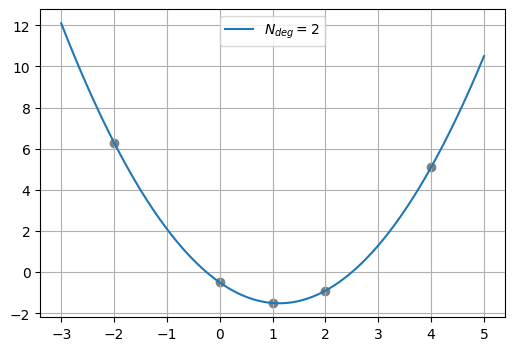

In [ ]:
class OLSFitPoly:
    def __init__(self, Ndegree):
        self.Ndegree = Ndegree

    def _design_matrix(self, X):  # underscore imply that the function is intened for use only INSIDE the class
        # construct the design matrix and determine beta
        Xaug = np.zeros((len(X), 1+self.Ndegree))
        for i, x in enumerate(X):
            for j, power in enumerate(range(1+self.Ndegree)):
                Xaug[i,j] = x**power
        return Xaug

    def fit(self, X, y, printing=False):
        Xaug = self._design_matrix(X)
        self.beta = np.linalg.inv(Xaug.T@Xaug)@(Xaug.T@y)
        if printing:
            print(Xaug)
            print(self.beta)
        
    def predict(self, X):
        Xaug = self._design_matrix(X)
        y = Xaug @ self.beta
        return y
    
    def plot(self, ax, X):
        ax.plot(X, self.predict(X), label=r'$N_{deg}=$'+f'{self.Ndegree}')
        ax.grid()
        ax.legend(loc='upper center')

fig, ax = plt.subplots(1,1,figsize=(6,4))
ols = OLSFitPoly(Ndegree=2)
ols.fit(xs, ys, printing=True)  # fit with sampled values
ols.plot(ax, x_lin)  # plot with smooth values
ax.scatter(xs, ys, c='grey')

*Why does the fitted curve reproduce the sampled function exactly?*

It does so because we provide Ndegree = 2 for a polynomial of 2. order.

Because we are estimating three coefficients, a minimum of 3 sampled points must be provided for an exact solution.

### Task 3 Fit noisy data

[[ 1.         -2.17751082  4.74155339]
 [ 1.         -0.30656631  0.0939829 ]
 [ 1.          0.90740434  0.82338263]
 [ 1.          2.3635847   5.58653263]
 [ 1.          4.21534581 17.76914026]]
[-0.79613318 -1.76594322  0.75035824]


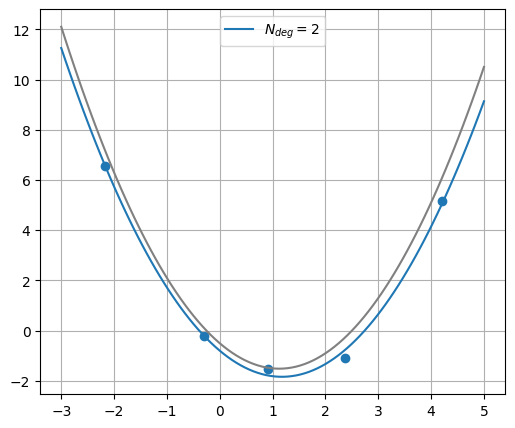

In [9]:
sigma=0.2
noisy_xs = np.array([np.random.normal(x, sigma) for x in xs])
noisy_ys = np.array([np.random.normal(y, sigma) for y in ys])
fig, ax = plt.subplots(1,1,figsize=(6,5))

noisy_ols = OLSFitPoly(Ndegree=2)
noisy_ols.fit(noisy_xs, noisy_ys, printing=True)
noisy_ols.plot(ax, x_lin)

ax.scatter(noisy_xs, noisy_ys, c='C0')
ax.plot(x_lin, y_lin, c='grey')

As the standard deviation increases, the coefficients vary more.

The function we try and fit to is not longer necessarily a 2. order polynomial, so the fitted curve does not pass through all points.

### Task 4: sample a double-well potential

In [10]:
class  DoubleWell():
    def __init__(self ,k=1, x0= 0, A=-1, x1=1.5 , l=0.25, xmin=-3, xmax=3):
        self.k = k
        self.x0 = x0
        self.A = A
        self.x1 = x1
        self.l = l

        self.xmin = xmin
        self.xmax = xmax
        self.xspace = np.linspace(self.xmin, self.xmax, 200)
        self.energies = self.potential_energy(self.xspace)
        self.forces = self.force(self.xspace)
        self.integrated_forces = self.integrated_force(self.xspace)

    def potential_energy(self , x):
        return 1/2 * self.k * (x-self.x0)**2 + self.A * np.exp(-(x-self.x1)**2/self.l/self.l)
    
    def force(self, x):
        # F = -dU/dx
        return -self.k*(x-self.x0)+(2*self.A*(x-self.x1)*np.exp(-(x-self.x1)**2/self.l/self.l))/self.l/self.l

    def integrated_force(self, x):
        integrated = []
        for i in range(0, len(x)):
            integration_space = np.linspace(self.x0, x[i])
            force_space = self.force(integration_space)
            integral = np.trapezoid(force_space, integration_space)
            integrated.append(self.potential_energy(self.x0) - integral)
        return integrated

    def plot(self, ax):
        ax.plot(self.xspace, self.energies, c='grey')
        # ax.plot(self.xspace, self.integrated_forces, 'r:', linewidth=3, label=r"$E(x_0)-\int_{x_0}^{x}f(x')dx'$")
        # ax.legend()
    

class  MolDynSystem ():
    def __init__(self, calc, x=0, kT=0.15):
        self.calc = calc
        self.x = x
        self.v = 0
        self.kT = kT
        self.k = self.calc.k
        self.x0 = self.calc.x0

    def potential_energy(self):
        return self.calc.potential_energy(self.x)
    
    def force(self):
        return self.calc.force(self.x)
    
    def get_position(self):
        return self.x
    
    def set_position(self, x):
        self.x = x

    def get_velocity(self):
        return self.v
    
    def set_velocity(self, v):
        self.v = v

    def thermal_avg(self, xs):
        return np.mean([self.calc.potential_energy(x) for x in xs])

    def thermal_fluctuations(self, xs):
        V = np.array([self.calc.potential_energy(x) for x in xs])

        V_avg = np.mean(V)
        V2_avg = np.mean(V**2)

        return (V2_avg - V_avg**2) / self.kT**2

In [11]:
def velocity_verlet(mdsys, N=100):
    rs = []
    for _ in range(N):
        dt = 0.01
        r = mdsys.get_position()
        v = mdsys.get_velocity()
        a_t = mdsys.force() # assume m=1

        # 1. update position
        r += v*dt + 1/2*a_t*dt**2
        mdsys.set_position(r)

        # 2. evaluate force and acceleration at new step
        a_t_dt = mdsys.force() # for harmonic osciallor F = -kx

        # 3. velocity update
        v += 1/2 * (a_t + a_t_dt)*dt
        mdsys.set_velocity(v)
        rs.append(r)
    return rs

Text(0, 0.5, '$V(x),P(x)$')

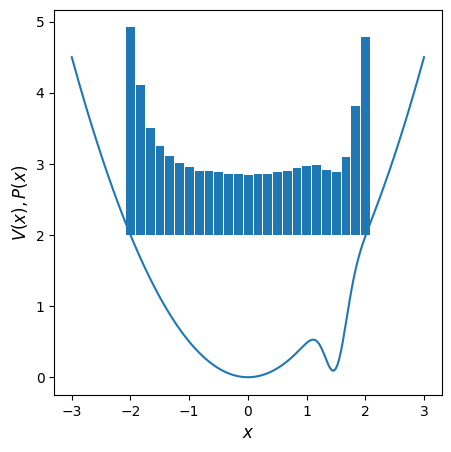

In [12]:
double_well = DoubleWell()

md = MolDynSystem(double_well, x=-2, kT=0.15)
# Now get the positions from the molecular dynamics simulation
timesteps = 10000
xs = velocity_verlet(md, N=timesteps)

fig, ax = plt.subplots(1,1,figsize=(5,5))

ax.plot(double_well.xspace, double_well.energies)
N_bins = 25
bin_shift = abs(max(xs)-min(xs))/N_bins/2 # to center bins
counts, bin_edges = np.histogram(xs, bins=N_bins, range=(min(xs)-bin_shift, max(xs)+bin_shift))
bin_width = bin_edges[1] - bin_edges[0]
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
P = counts/(len(xs)*bin_width) * 5  # scale by 5
ax.bar(bin_centers, P, width=bin_width*0.9, bottom=2)
ax.set_xlabel(r'$x$', size=12)
ax.set_ylabel(r'$V(x),P(x)$', size=12)

[ 1.10479007 -1.21892392  1.99818981 -0.31890438  1.68678621 -1.94777921
  1.49068851  1.33676116]
[0.52811788 0.74288776 1.97752838 0.05085    0.85040021 1.89692192
 0.11246242 0.24057786]


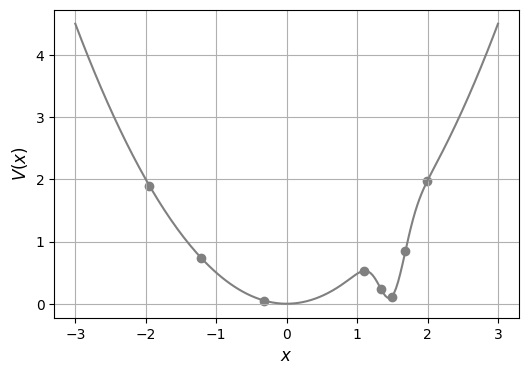

In [13]:
# select eight positions:

# sampled_xs = []
# while len(sampled_xs) < 8:
#     i = np.random.randint(timesteps)
#     x_pos = xs[i]
#     if all(abs(x_pos - pos) >= 0.05 for pos in sampled_xs):  #ensure seperation
#         if len(sampled_xs) <= 5:
#             sampled_xs.append(x_pos)
#             print(i)
#         if len(sampled_xs) > 5 and abs(x_pos - 1.5) <= 0.2:
#             sampled_xs.append(x_pos)
#             print(i)
sampled_xs = [xs[8550], xs[5266], xs[306], xs[6094], xs[6796], xs[8907], xs[2144], xs[823]]
sampled_xs = np.array(sampled_xs)
sampled_ys = double_well.potential_energy(sampled_xs)
print(sampled_xs)
print(sampled_ys)

fig, ax = plt.subplots(1,1,figsize=(6,4))
double_well.plot(ax)
ax.scatter(sampled_xs, sampled_ys, c='grey')
ax.set_xlabel(r'$x$', size=12)
ax.set_ylabel(r'$V(x)$', size=12)
ax.grid()

Text(0, 0.5, '$V(x)$')

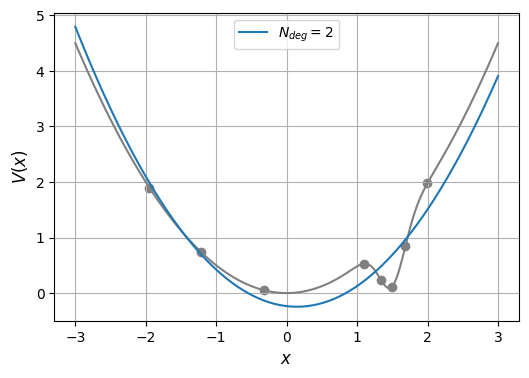

In [14]:
osl_dw = OLSFitPoly(Ndegree=2)
osl_dw.fit(sampled_xs, sampled_ys)

fig, ax = plt.subplots(1,1,figsize=(6,4))
double_well.plot(ax)
osl_dw.plot(ax, np.linspace(-3,3,100))
ax.scatter(sampled_xs, sampled_ys, c='grey')
ax.set_xlabel(r'$x$', size=12)
ax.set_ylabel(r'$V(x)$', size=12)

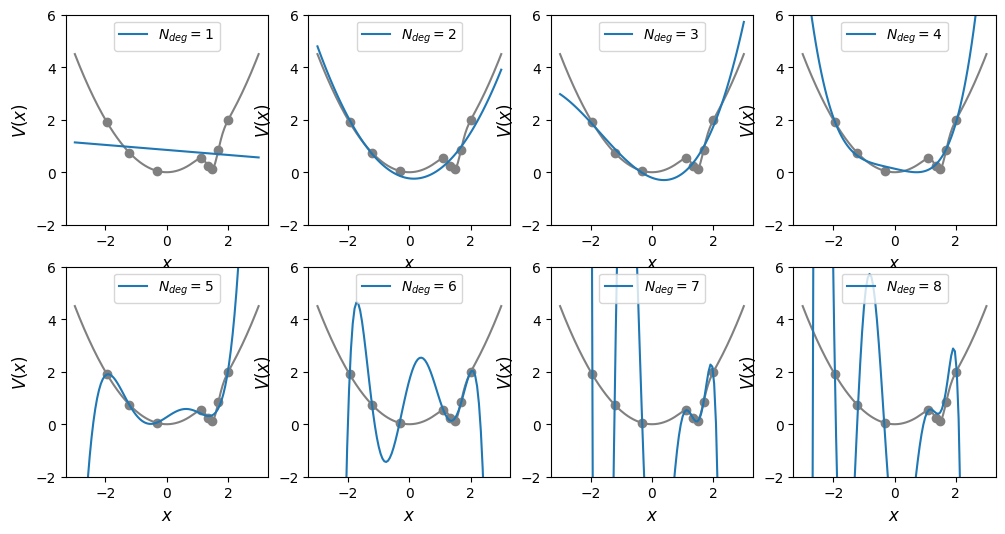

In [15]:
fig, axes = plt.subplots(2,4,figsize=(12,6))

for i, ax in enumerate(axes.flatten()):
    osl = OLSFitPoly(Ndegree=i+1)
    osl.fit(sampled_xs, sampled_ys)
    double_well.plot(ax)
    osl.plot(ax, np.linspace(-3,3,100))
    ax.scatter(sampled_xs, sampled_ys, c='grey')
    ax.set_xlabel(r'$x$', size=12)
    ax.set_ylabel(r'$V(x)$', size=12)
    ax.set_ylim(-2,6)
    ax.grid()


With a polynomial of degree $p$, there will always be $p+1$ fitting parameters. Thus with 8 points, an exact solution can be found with $p=7$ (8 equations with 8 unknown variables). This is why we see the fit go through all points at $p=7$.

When there are more parameters than data points, $X_{aug}^TX_{aug}$ is a singular matrix, meaning that rows or coloums can be constructed from each other. That in turn means the determinant is zero and the inverse does not exists. This gives infinite possible solutions for the fitting parameters.

Passing through all data points exactly does not imply that it is a "good" fit with a useful representation. Looking at $p=7$, the fit does not represent the original double well potential at all.

# W08B Ridge regression

In the previous exercise, the solution is unstable when there are too few points to the number of parameters. With Ridge Regression we regularize the fit.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [55]:
sampled_xs = np.array([1.10479007, -1.21892392, 1.99818981, -0.31890438, 1.68678621, -1.94777921, 1.49068851, 1.33676116])
sampled_ys = np.array([0.52811788, 0.74288776, 1.97752838, 0.05085, 0.85040021, 1.89692192, 0.11246242, 0.24057786])

def double_well_pot(x, k=1, x0=0, A=-1, x1=1.5 , l=0.25):
    return 1/2 * k * (x-x0)**2 + A * np.exp(-(x-x1)**2/l/l)

class OLSFitPoly:
    def __init__(self, Ndegree):
        self.Ndegree = Ndegree

    def _design_matrix(self, X):  # underscore imply that the function is intened for use only INSIDE the class
        Xaug = np.zeros((len(X), 1+self.Ndegree))
        for i, x in enumerate(X):
            for j, power in enumerate(range(1+self.Ndegree)):
                Xaug[i,j] = x**power
        return Xaug

    def fit(self, X, y, printing=False):
        # construct the design matrix and determine beta
        Xaug = self._design_matrix(X)
        self.beta = np.linalg.inv(Xaug.T@Xaug)@(Xaug.T@y)
        if printing:
            print(self.beta)
        
    def predict(self, X):
        Xaug = self._design_matrix(X)
        y = Xaug @ self.beta
        return y
    
    def plot(self, ax, X, c='C0'):
        ax.plot(X, self.predict(X), c=c, label='OSL, '+r'$p=$'+f'{self.Ndegree}')
        ax.grid()
        ax.legend()

class RidgeRegressionPoly:
    def __init__(self, Ndegree, log10l):
        self.Ndegree = Ndegree
        self.l = 10**log10l

    def _design_matrix(self, X):  # underscore imply that the function is intened for use only INSIDE the class
        Xaug = np.zeros((len(X), 1+self.Ndegree))
        for i, x in enumerate(X):
            for j, power in enumerate(range(1+self.Ndegree)):
                Xaug[i,j] = x**power
        return Xaug

    def fit(self, X, y, printing=False):
        # construct the design matrix and determine beta
        Xaug = self._design_matrix(X)
        self.beta = np.linalg.inv(Xaug.T@Xaug + self.l*np.identity(Xaug.shape[1])) @ (Xaug.T@y)
        if printing:
            print(self.beta)
        
    def predict(self, X):
        Xaug = self._design_matrix(X)
        y = Xaug @ self.beta
        return y
    
    def plot(self, ax, X, c='C0'):
        ax.plot(X, self.predict(X), c=c, label='RR, '+r'$p=$'+f'{self.Ndegree}, '+r'$\lambda$='+f'{self.l:.0e}')
        ax.grid()
        ax.legend()

[ 0.27223596  0.76119433  0.04350919 -0.87888783  0.09393082  0.17489484]
[ 0.10376068 -0.01493536  0.07650787 -0.1935072   0.09722007  0.04831167]


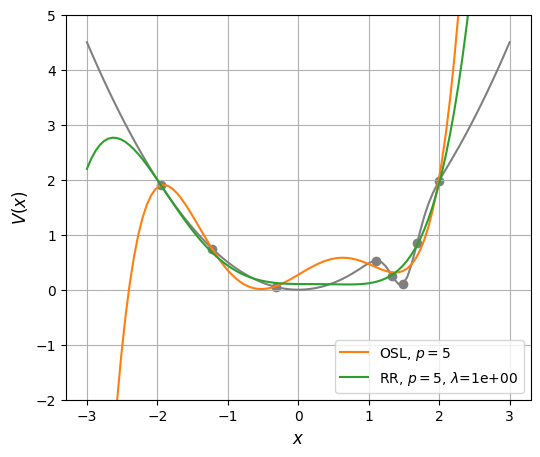

In [56]:
osl = OLSFitPoly(Ndegree=5)
osl.fit(sampled_xs, sampled_ys, printing=True)
rr = RidgeRegressionPoly(Ndegree=5, log10l=0)
rr.fit(sampled_xs, sampled_ys, printing=True)

x_lin = np.linspace(-3,3,100)
y_lin = double_well_pot(x_lin)
fig, ax = plt.subplots(1,1,figsize=(6,5))
ax.scatter(sampled_xs, sampled_ys, c='grey')
ax.plot(x_lin,y_lin, c='grey')
osl.plot(ax, x_lin, c='C1')
rr.plot(ax, x_lin, c='C2')
ax.set_ylim(-2, 5)
ax.set_xlabel(r'$x$', size=12)
ax.set_ylabel(r'$V(x)$', size=12)
ax.grid()

RR is more smooth between points compared to OSL.

Comparing the coefficients, RR supresses larger coefficients, while OSL can have much larger coefficients.

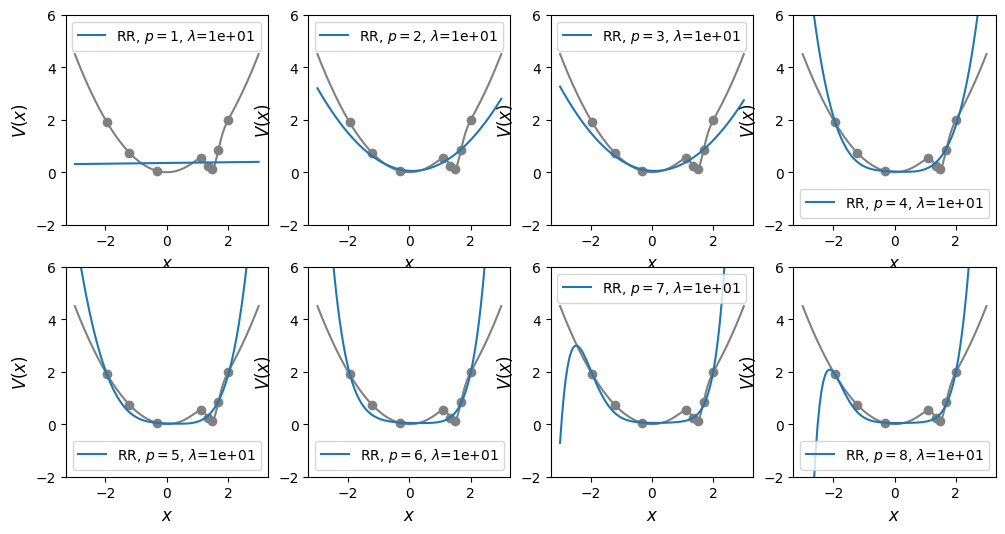

In [57]:
fig, axes = plt.subplots(2,4,figsize=(12,6))

for i, ax in enumerate(axes.flatten()):
    rr = RidgeRegressionPoly(Ndegree=i+1, log10l=1)
    rr.fit(sampled_xs, sampled_ys)
    double_well.plot(ax)
    rr.plot(ax, np.linspace(-3,3,100))
    ax.scatter(sampled_xs, sampled_ys, c='grey')
    ax.set_xlabel(r'$x$', size=12)
    ax.set_ylabel(r'$V(x)$', size=12)
    ax.set_ylim(-2,6)
    ax.grid()

### Task 3: vary the regularization parameter

[ 0.35908286  0.94269165 -0.27374319 -1.06221594  0.32240277  0.21089067
 -0.0396479 ]
[ 0.1549384   0.25438305  0.28525085 -0.41973924 -0.07948262  0.08898198
  0.03104312]
[ 0.12878572 -0.01474538  0.14092431 -0.16249796  0.00649995  0.03994798
  0.01911191]
[ 0.04945407 -0.02874105  0.04971706 -0.04433712  0.03685613  0.00941387
  0.01909395]
[ 0.00920051 -0.00341095  0.01162528 -0.00506207  0.0162892  -0.00235548
  0.02770703]
[ 0.00153232 -0.00036352  0.00309383 -0.00074501  0.00833946 -0.001498
  0.02718689]
[3.90320118e-04 4.67115980e-05 1.13169243e-03 1.75995008e-04
 3.82073305e-03 6.89390999e-04 1.38603145e-02]
[5.97413463e-05 1.59516686e-05 1.84755813e-04 5.36070694e-05
 6.41425678e-04 1.93913773e-04 2.35230305e-03]


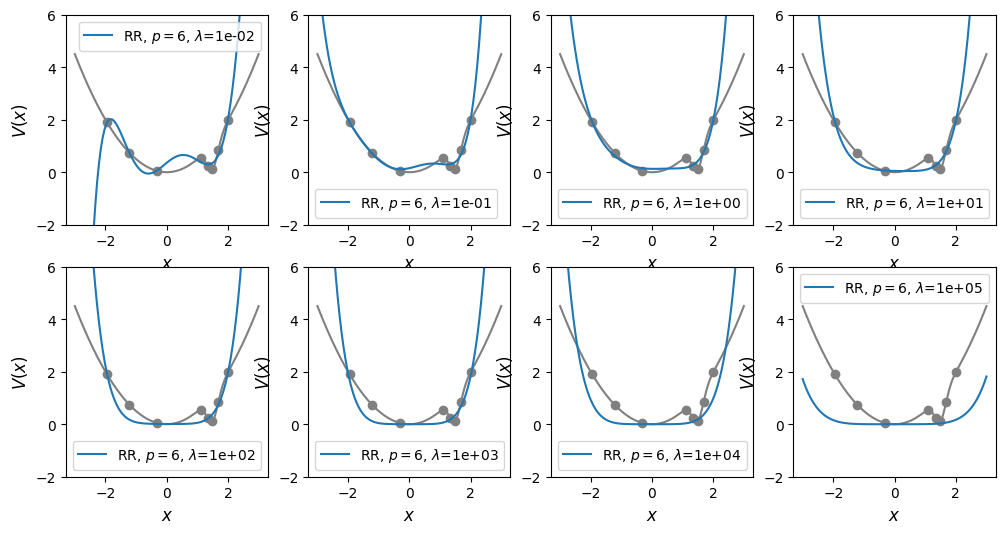

In [58]:
fig, axes = plt.subplots(2,4,figsize=(12,6))

for ax, log10l in zip(axes.flatten(), range(-2,6)):
    rr = RidgeRegressionPoly(Ndegree=6, log10l=log10l)
    rr.fit(sampled_xs, sampled_ys, printing=True)
    double_well.plot(ax)
    rr.plot(ax, np.linspace(-3,3,100))
    ax.scatter(sampled_xs, sampled_ys, c='grey')
    ax.set_xlabel(r'$x$', size=12)
    ax.set_ylabel(r'$V(x)$', size=12)
    ax.set_ylim(-2,6)
    ax.grid()

From weak to strong regularization, the ridge regression cares more about supressing the coefficients than going through all points.

When $\lambda\rightarrow0$, we predict the same as OLS, since we recover the formula for OLS.

When $\lambda\rightarrow\infty$, we predict that all coefficients go towards zero, and we would get a flat line.

$\lambda I$ should be on the same order of magnitude as $X_{aug}^T X_{aug}$ for the regression to be reasonable. Too small $\lambda$ would recover OLS and too large $\lambda$ would supress the coefficients. So $\lambda\in[0.1, 10]$

### Task 4: include a prior model

In [ ]:
class RidgeRegressionExt:
    def __init__(self, prior, Ndegree, log10l):
        self.Ndegree = Ndegree
        self.l = 10**log10l
        self.prior = prior

    def _design_matrix(self, X):  # underscore imply that the function is intened for use only INSIDE the class
        # construct the design matrix and determine beta
        Xaug = np.zeros((len(X), 1+self.Ndegree))
        for i, x in enumerate(X):
            for j, power in enumerate(range(1+self.Ndegree)):
                Xaug[i,j] = x**power
        return Xaug

    def fit(self, X, y, printing=False):
        Xaug = self._design_matrix(X)
        residuals = y - self.prior.predict(X)
        self.beta = np.linalg.inv(Xaug.T@Xaug + self.l*np.identity(Xaug.shape[1])) @ (Xaug.T@residuals)
        if printing:
            print(self.beta)
        
    def predict(self, X):
        Xaug = self._design_matrix(X)
        y = self.prior.predict(X) + Xaug @ self.beta
        return y
    
    def plot(self, ax, X, c='C0'):
        ax.plot(X, self.predict(X), c=c, label='RR, '+r'$p=$'+f'{self.Ndegree}, '+r'$\lambda$='+f'{self.l:.0e}')
        ax.grid()
        ax.legend()

[-0.4637683   1.08209794 -0.33647361 -1.10336273  0.3622927   0.21872872
 -0.04626675]
[-0.6083507   0.3759141   0.18075505 -0.44023922 -0.03961801  0.09260444
  0.02623349]
[-0.36221261  0.06351408 -0.01921392 -0.13129704 -0.04219528  0.03277432
  0.03633609]
[-0.10923646 -0.01343752 -0.07039258 -0.04571829 -0.07644994  0.01485521
  0.04391177]
[-0.02147769 -0.00873169 -0.02175085 -0.01441724 -0.02334178  0.00463106
  0.02410848]
[-2.29364725e-03 -1.15436915e-03 -1.91061888e-03 -1.78869580e-03
  6.22007769e-05  7.20393755e-04  1.43846625e-02]
[-1.20167939e-04 -6.94662538e-05  1.97605976e-04 -2.81124595e-05
  1.43590630e-03  6.08060014e-04  6.81014840e-03]
[-2.05283545e-06 -1.23027686e-06  5.42822404e-05  1.56091951e-05
  2.68792760e-04  1.25139631e-04  1.14778141e-03]


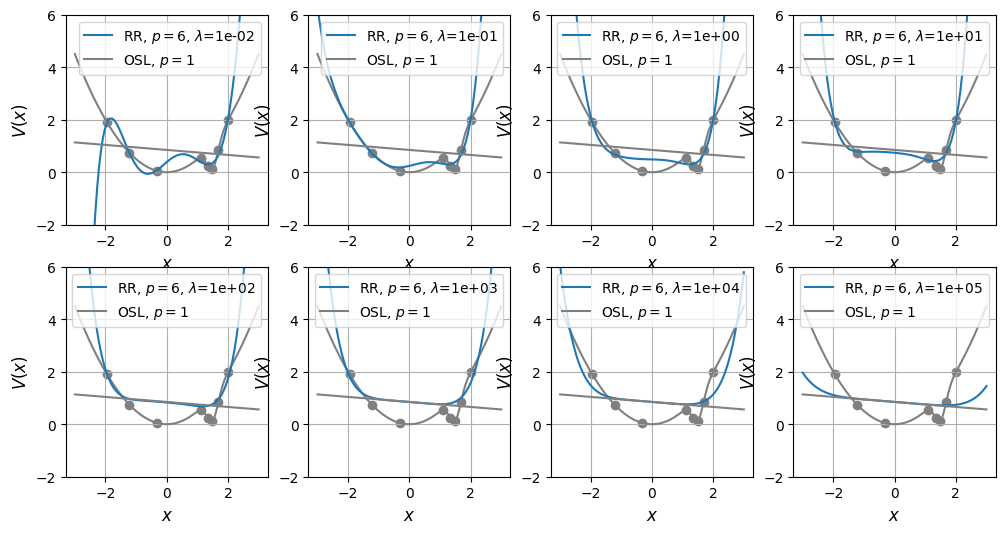

In [62]:
fig, axes = plt.subplots(2,4,figsize=(12,6))

osl_prior = OLSFitPoly(Ndegree=1)
osl_prior.fit(sampled_xs, sampled_ys)

for ax, log10l in zip(axes.flatten(), range(-2,6)):
    rr = RidgeRegressionExt(prior=osl_prior, Ndegree=6, log10l=log10l)
    rr.fit(sampled_xs, sampled_ys, printing=True)
    double_well.plot(ax)
    rr.plot(ax, np.linspace(-3,3,100))
    osl_prior.plot(ax, np.linspace(-3,3,100), c='grey')
    ax.scatter(sampled_xs, sampled_ys, c='grey')
    ax.set_xlabel(r'$x$', size=12)
    ax.set_ylabel(r'$V(x)$', size=12)
    ax.set_ylim(-2,6)
    ax.grid()

When $\lambda$ increases, the coefficients ($\beta$) gets small. That means:
$f(x)=f_{prior}+\sum_j \beta_j\phi_j(x)\rightarrow f_{prior}$ 

Thus as $\lambda\rightarrow\infty$ we expect it to follow the prior function, and so it does.

This provides an advantage if there are few data points but we know a prior function. For instance we may know that it should mainly follow a second degree polynomial, and using that as a prior function, fewer data points may be needed to get an acccurate estimate.

# W08C Kernel ridge regression with a Gaussian kernel

In [3]:
import numpy as np
import matplotlib.pyplot as plt

### Task 1: implement the Gaussian kernel

In [4]:
class GaussianKernel():
    def __init__(self, sigma):
        self.sigma = sigma

    def __call__(self, x1, x2):
        x1 = np.atleast_1d(x1)  # ensures that the next part of the code works as intented
        x2 = np.atleast_1d(x2)  # i.e. also for integer inputs
        return np.exp(-(x1[:, None]-x2[None, :])**2/(2*self.sigma**2))  # numpy broadcasting

K = GaussianKernel(sigma=2)
K(1,2)

array([[0.8824969]])

### Task 2: evaluate the kernel between one point and several points

In [5]:
X = np.array([1, 2, 5])
K(1, X)

array([[1.        , 0.8824969 , 0.13533528]])

$\sigma$ determines how quickly the kernel value decrease as the distance between points increase. A larger $\sigma$ will make the decrease slower, and vice verca.

### Task 3: construct the kernel matrix

In [6]:
K(X,X)

array([[1.        , 0.8824969 , 0.13533528],
       [0.8824969 , 1.        , 0.32465247],
       [0.13533528, 0.32465247, 1.        ]])

The diagonal is 1, since the distance is 0 and $\exp(0)=1$

The matrix is symmetric, since the distance between $x_i$ and $x_j$ is the same as the distance between $x_j$ and $x_i$.

### Task 4: fit data with kernel ridge regression

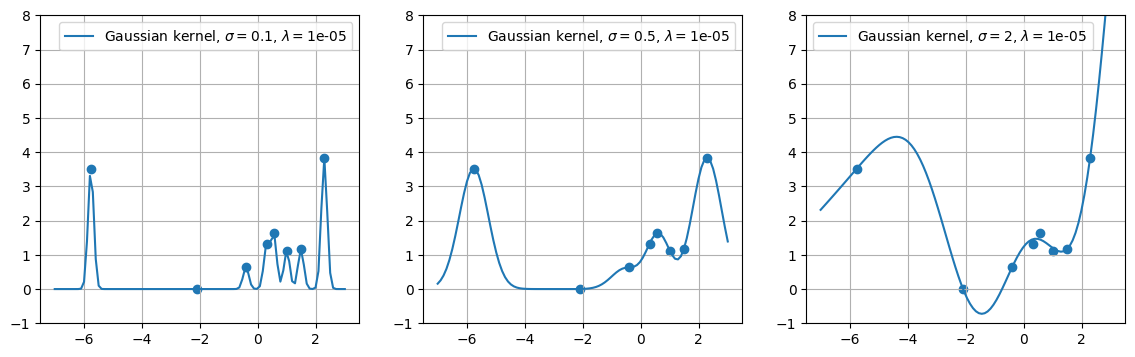

In [14]:
class KernelRidgeRegression():
    def __init__(self, kernel, log10l=-1):
        self.kernel = kernel
        self.l = 10**log10l

    def _K(self, x1, x2):
        return self.kernel(x1,x2)

    def fit(self, X, y):
        self.X_train = X
        K = self._K(X, X)
        self.alpha = np.linalg.inv(K + self.l*np.identity(K.shape[1])) @ y

    def predict(self, X):
        K = self._K(X, self.X_train)
        y_pred = K @ self.alpha
        return y_pred

    def plot(self, ax, X, c='C0'):
        ax.plot(X, self.predict(X), c=c, label='Gaussian kernel, '+r'$\sigma=$'+f'{self.kernel.sigma}, '+r'$\lambda=$'+f'{self.l:.0e}')
        ax.grid()
        ax.legend()


xs = np.array([1.00073656, 2.29030314, -2.09037468, 
               -5.75259232, 0.30391792, 0.55216248,
               1.48650712, -0.40884007])
ys = np.array([1.12573393e+00, 3.83712913e+00,
               2.04189572e-03, 3.52048728e+00,
               1.32700944e+00, 1.62773413e+00,
               1.17096493e+00, 6.32947483e-01])

fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, sigma in zip(axes, [0.1, 0.5, 2]):
    gaussian_kernel = GaussianKernel(sigma=sigma)
    krr = KernelRidgeRegression(kernel=gaussian_kernel, log10l=-5)
    ax.scatter(xs, ys)
    krr.fit(xs, ys)
    krr.plot(ax, np.linspace(-7,3,100))
    ax.set_ylim(-1,8)



With low $\sigma$, change in values are more rapid, so as $\sigma$ increases, the values change more smoothly.

### Task 5: introduce a constant prior

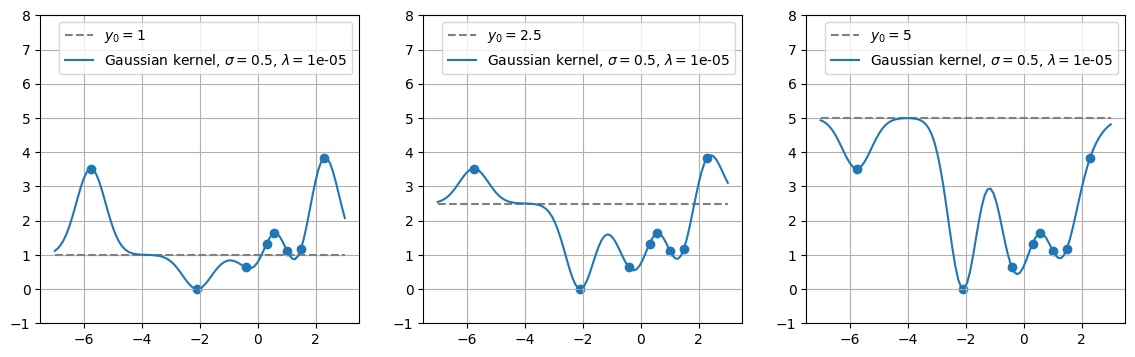

In [15]:
class KernelRidgeRegressionConst(KernelRidgeRegression):
    def __init__(self, y0, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.y0 = y0

    def fit(self, X, y):
        self.X_train = X
        K = self._K(X, X)
        self.alpha = np.linalg.inv(K + self.l*np.identity(K.shape[1])) @ (y - self.y0)

    def predict(self, X):
        K = self._K(X, self.X_train)
        y_pred = K @ self.alpha + self.y0
        return y_pred

    def plot(self, ax, X, c='C0'):
        ax.plot(X, [self.y0]*len(X), c='grey', ls='--', label=r'$y_0=$'+f'{self.y0}')
        super().plot(ax, X, c)


fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, y0 in zip(axes, [1, 2.5, 5]):
    gaussian_kernel = GaussianKernel(sigma=0.5)
    krr = KernelRidgeRegressionConst(kernel=gaussian_kernel, y0=y0, log10l=-5)
    ax.scatter(xs, ys)
    krr.fit(xs, ys)
    krr.plot(ax, np.linspace(-7,3,100))
    ax.set_ylim(-1,8)

Now with the prior function, the prediction far away the training data approaches the prior functions value, instead of simply approaching zero.

### Task 6: investigate a nonconstant prior and regularization

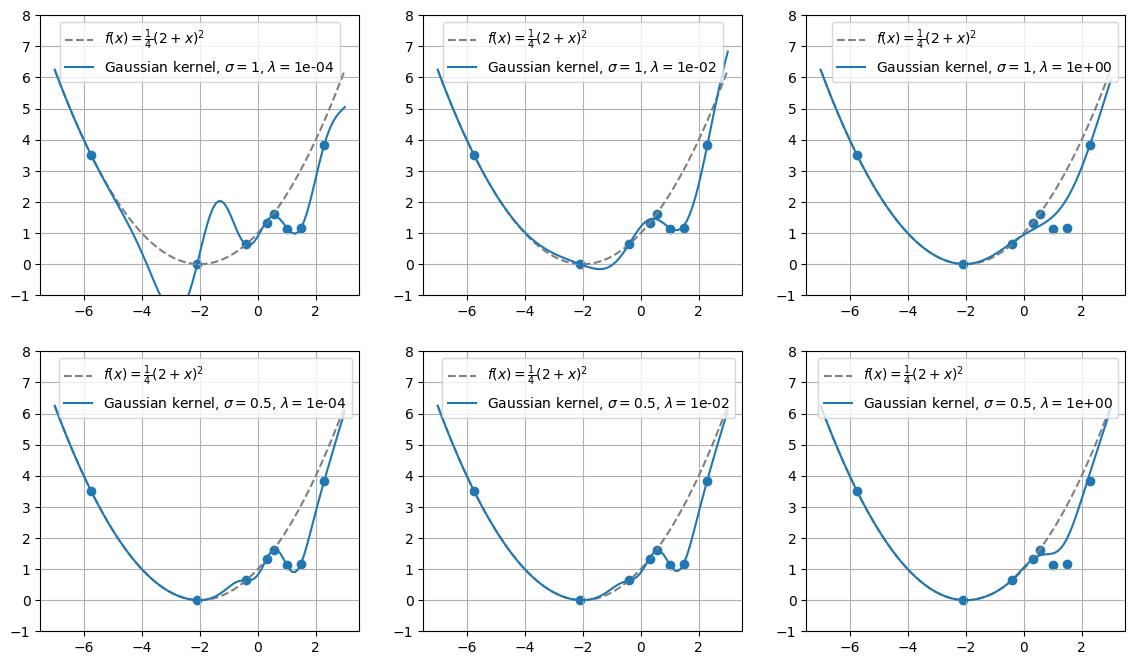

In [53]:
class KernelRidgeRegressionExt(KernelRidgeRegression):
    def __init__(self, f, f_label=r'$f(x)$', *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.f = f
        self.f_label = f_label

    def fit(self, X, y):
        self.X_train = X
        K = self._K(X, X)
        self.alpha = np.linalg.inv(K + self.l*np.identity(K.shape[1])) @ (y - self.f(X))

    def predict(self, X):
        K = self._K(X, self.X_train)
        y_pred = K @ self.alpha + self.f(X)
        return y_pred

    def plot(self, ax, X, c='C0'):
        ax.plot(X, self.f(X), c='grey', ls='--', label=self.f_label)
        super().plot(ax, X, c)


fig, axes = plt.subplots(2,3,figsize=(14,8))
for ax, log10l in zip(axes[0], [-4, -2, 0]):
    gaussian_kernel = GaussianKernel(sigma=1)
    krr = KernelRidgeRegressionExt(kernel=gaussian_kernel, f=lambda x: 1/4*(x+2)**2, f_label=r'$f(x)=\frac{1}{4} (2+x)^2$', log10l=log10l)
    ax.scatter(xs, ys)
    krr.fit(xs, ys)
    krr.plot(ax, np.linspace(-7,3,100))
    ax.set_ylim(-1,8)
for ax, log10l in zip(axes[1], [-4, -2, 0]):
    gaussian_kernel = GaussianKernel(sigma=0.5)
    krr = KernelRidgeRegressionExt(kernel=gaussian_kernel, f=lambda x: 1/4*(x+2)**2, f_label=r'$f(x)=\frac{1}{4} (2+x)^2$', log10l=log10l)
    ax.scatter(xs, ys)
    krr.fit(xs, ys)
    krr.plot(ax, np.linspace(-7,3,100))
    ax.set_ylim(-1,8)

As $\lambda\rightarrow\infty$, $\alpha\rightarrow 0$. Therefore the prediction is just $f(x)$.

As $\lambda\rightarrow 0$, the prediction follows the points more closely.

# W08D Implicit feature mappings of kernels

In [13]:
import numpy as np
import matplotlib.pyplot as plt

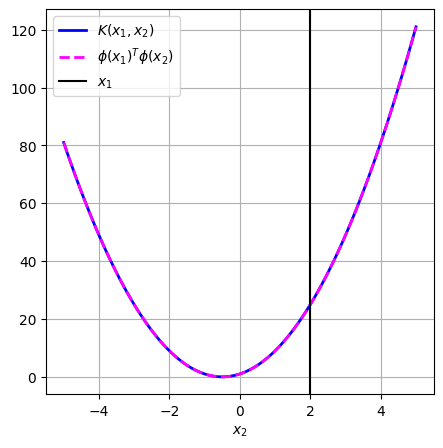

In [14]:
K = lambda x1, x2: (1 + x1*x2)**2
phi = lambda x: np.array([np.ones_like(x), np.sqrt(2)*x, x**2])
# np.ones_like makes an array of ones in the shape of x

x1 = 2
x2 = np.linspace(-5, 5, 100)

fig, ax = plt.subplots(1,1,figsize=(5,5))
ax.plot(x2, K(x1, x2), c='blue', ls='-', lw=2, label=r'$K(x_1,x_2)$')
ax.plot(x2, phi(x1).T @ phi(x2), c='magenta', ls='--', lw=2, label=r'$\phi(x_1)^T\phi(x_2)$')
ax.axvline(x1, c='k', label=r'$x_1$')
ax.set_xlabel(r'$x_2$')
ax.legend()
ax.grid()

### Task 2: parity plot for the polynomial kernel

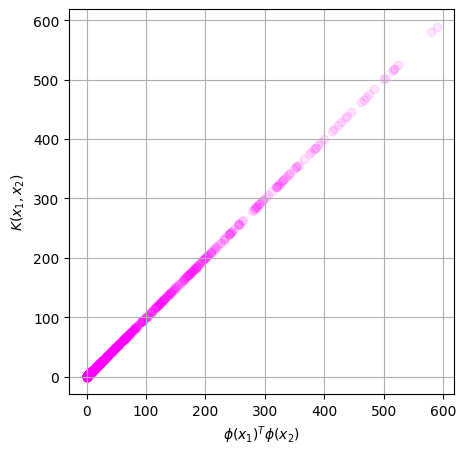

In [15]:
pairs = [[np.random.uniform(-5, 5), np.random.uniform(-5, 5)] for _ in range(1000)]

fig, ax = plt.subplots(1,1,figsize=(5,5))
for (x1, x2) in pairs:
    ax.scatter(phi(x1).T @ phi(x2), K(x1, x2), c='magenta', alpha=0.1)
ax.set_ylabel(r'$K(x_1,x_2)$')
ax.set_xlabel(r'$\phi(x_1)^T\phi(x_2)$')
ax.set_aspect('equal')
ax.grid()

Since the corresponding feature mapping to $K$ is $\phi$, the two axis should be equal. Thus the points on the parity plot should follow a line of $x=y$ or in this case $K(x_1,x_2)=\phi(x_1)^T\phi(x_2)$

### Task 3: a discrete feature mapping of the RBF kernel

In [16]:
class GaussianKernel():
    def __init__(self, sigma):
        self.sigma = sigma

    def __call__(self, x1, x2):
        x1 = np.atleast_1d(x1)  # ensures that the next part of the code works as intented
        x2 = np.atleast_1d(x2)  # i.e. also for integer inputs
        return np.exp(-(x1[:, None]-x2[None, :])**2/(2*self.sigma**2))  # numpy broadcasting

class DiscreteRBF:
    def __init__(self, sigma, dx):
        self.sigma = sigma
        self.dx = dx
        self.grid_points = np.arange(-5, 5, self.dx)

    def __call__(self, x):
        sigma_phi = self.sigma/np.sqrt(2)
        A = np.sqrt(np.sqrt(2*np.pi)*self.sigma)
        feature_vector = A * 1/(np.sqrt(2*np.pi)*sigma_phi) * np.exp(-(x-self.grid_points)**2/(2*sigma_phi**2))*np.sqrt(self.dx)
        return feature_vector

x1 = 0.25
x2 = 0.50

K = GaussianKernel(sigma=0.1)
print(f'K(x1,x2) = {K(x1, x2).item():.10f}\n')
print(f"{'dx':<10}{'phi(x1)^T phi(x1)':<25}{'phi(x2)^T phi(x2)':<25}{'phi(x1)^T phi(x2)':<25}")
print("-" * 80)
for dx in [0.1, 0.04, 0.02, 0.008, 0.0016, 0.00032, 0.000064]:
    dx*=5
    phi = DiscreteRBF(sigma=0.1, dx=dx)
    phi_1 = (phi(x1).T @ phi(x1)).item()
    phi_2 = (phi(x2).T @ phi(x2)).item()
    phi_12 = (phi(x1).T @ phi(x2)).item()
    print(f"{dx:<10.6g}{phi_1:<25.10f}{phi_2:<25.10f}{phi_12:<25.10f}")

K(x1,x2) = 0.0439369336

dx        phi(x1)^T phi(x1)        phi(x2)^T phi(x2)        phi(x1)^T phi(x2)        
--------------------------------------------------------------------------------
0.5       0.0000297344             3.9894228040             0.0077013978             
0.2       0.9856162386             0.4319277807             0.0620308647             
0.1       0.9856162386             1.0143837721             0.0439369334             
0.04      1.0000000000             1.0000000000             0.0439369336             
0.008     1.0000000000             1.0000000000             0.0439369336             
0.0016    1.0000000000             1.0000000000             0.0439369336             
0.00032   1.0000000000             1.0000000000             0.0439369336             


A course grid may miss the Gaussian. In this case with $\sigma=0.1$, the peak of the Gaussian is quite narrow, and a step size og $0.5$ is too big to capture enough information about the Gaussian for the feature mapping.

*If the grid spacing $\Delta x$ is too large compared with the width of the Gaussian, the discrete feature map may not capture the shape of the Gaussian accurately.*

With a reduced step size, $\Delta x$, more $\phi_i(x)$ can be computed, thus increasing the dimensionality of $\Phi(x)$ 

### Task 4: visualize the discrete RBF feature vectors

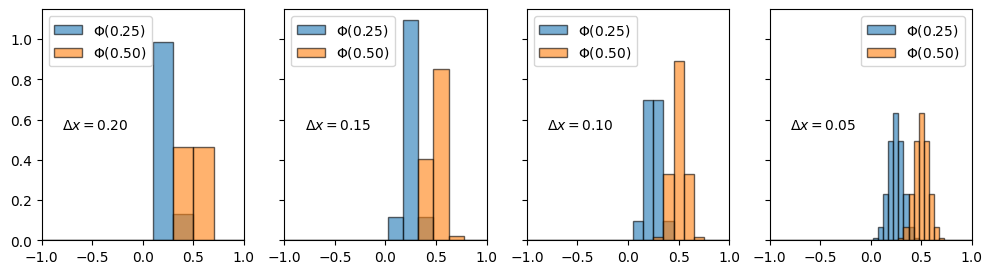

In [17]:
fig, axes = plt.subplots(1,4,figsize=(12,3), sharey=True)
for dx, ax in zip([0.20, 0.15, 0.10, 0.05], axes):
    phi = DiscreteRBF(sigma=0.1, dx=dx)
    ax.bar(phi.grid_points, phi(x1), width=dx, facecolor='C0', edgecolor='k', alpha=0.6, label=r'$\Phi(0.25)$')
    ax.bar(phi.grid_points, phi(x2), width=dx, facecolor='C1', edgecolor='k', alpha=0.6, label=r'$\Phi(0.50)$')
    ax.text(0.1, 0.5, r'$\Delta x=$'+f'{dx:.2f}', transform=ax.transAxes, ha='left', va='center')
    ax.set_xlim(-1,1)
    ax.legend()

As $\Delta x$ is reduced, the sampled shape looks more like a Gaussian. This is because of a higher discritized space, allowing for higher dimensionality of $\Phi$, therefore capturing more of the Gaussian shape.

Notice how the peak position of the two Gaussians ($x_1=0.25$ and $x_2=0.50$) is more apparent as $\Delta x$ is reduced. 

With $\Delta x=0.20$, all components are spread over just two discritized points. As $\Delta x$ is reduced, the components are more "spread out" to take the shape of the Gaussian.

### Task 5: recover the RBF kernel from feature-vector inner products

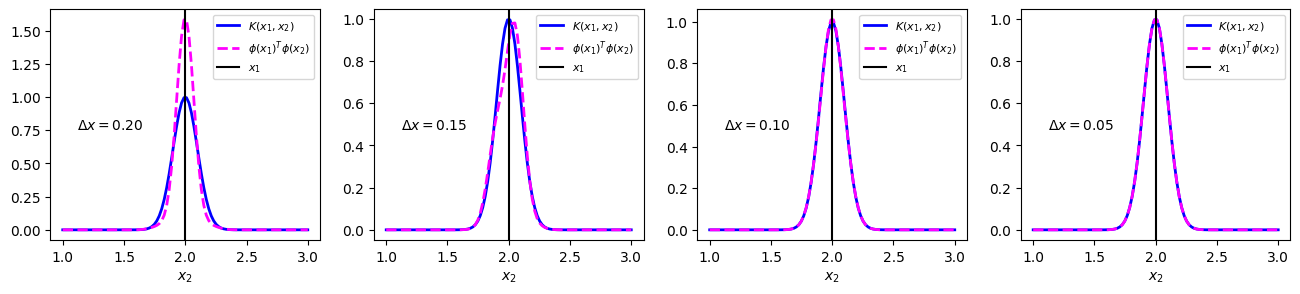

In [236]:
x1 = 2
x2 = np.linspace(1, 3, 100)

K = GaussianKernel(sigma=0.1)
fig, axes = plt.subplots(1,4,figsize=(16,3))
for dx, ax in zip([0.20, 0.15, 0.10, 0.05], axes):
    phi = DiscreteRBF(sigma=0.1, dx=dx)
    ax.plot(x2, K(x1, x2)[0], c='blue', ls='-', lw=2, label=r'$K(x_1,x_2)$')
    ax.plot(x2, [phi(x1).T @ phi(x) for x in x2], c='magenta', ls='--', lw=2, label=r'$\phi(x_1)^T\phi(x_2)$')
    ax.axvline(x1, c='k', label=r'$x_1$')
    ax.text(0.1, 0.5, r'$\Delta x=$'+f'{dx:.2f}', transform=ax.transAxes, ha='left', va='center')
    ax.set_xlabel(r'$x_2$')
    ax.legend(fontsize=8)

The agreement between the two depends on the size of $\Delta x$, with smaller $\Delta x$ yielding better agreement.

As $\Delta x\rightarrow 0$ the discreate feature map should completely coincide with the kernel. The key idea is that the inner product of the feature vectors is a Riemann sum approximating an integral.

### Task 6: parity plots for the RBF kernel

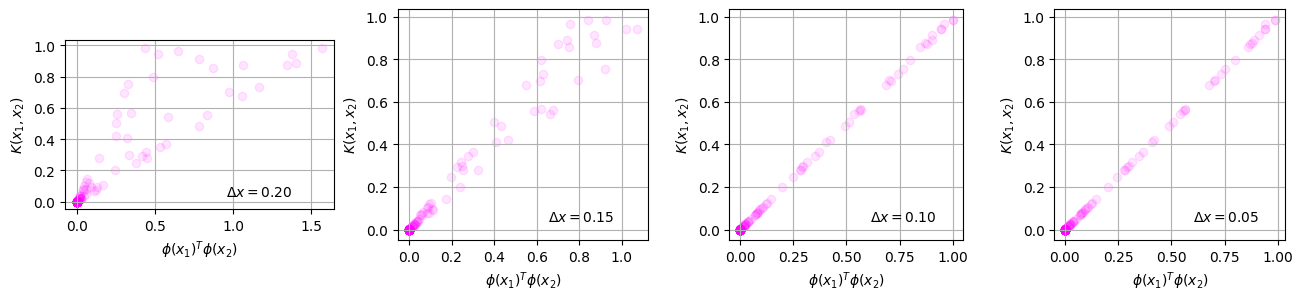

In [239]:
pairs = [[np.random.uniform(-5, 5), np.random.uniform(-5, 5)] for _ in range(1000)]

K = GaussianKernel(sigma=0.1)
fig, axes = plt.subplots(1,4,figsize=(16,3))
for dx, ax in zip([0.20, 0.15, 0.10, 0.05], axes):
    phi = DiscreteRBF(sigma=0.1, dx=dx)
    for (x1, x2) in pairs:
        ax.scatter(phi(x1).T @ phi(x2), K(x1, x2), c='magenta', alpha=0.1)
    ax.text(0.6, 0.1, r'$\Delta x=$'+f'{dx:.2f}', transform=ax.transAxes, ha='left', va='center')
    ax.set_ylabel(r'$K(x_1,x_2)$')
    ax.set_xlabel(r'$\phi(x_1)^T\phi(x_2)$')
    ax.set_aspect('equal')
    ax.grid()

This calculation demonstrates that a higher dimensional feature-vector coincides better with the kernel. 

This illustrates how a finite-dimensional approximation, i.e. the RBF kernel, can reproduce the inner products associated with an infinite-dimensional feature representation. It  demonstrates that the RBF kernel can be interpreted as an inner product in a feature space, and that kernel ridge regression can use this implicit feature mapping without explicitly constructing the feature vectors.

# W08E Kernel ridge regression with atomic descriptors 

In [116]:
import numpy as np
import matplotlib.pyplot as plt
from week04 import Morse, AtomicCluster

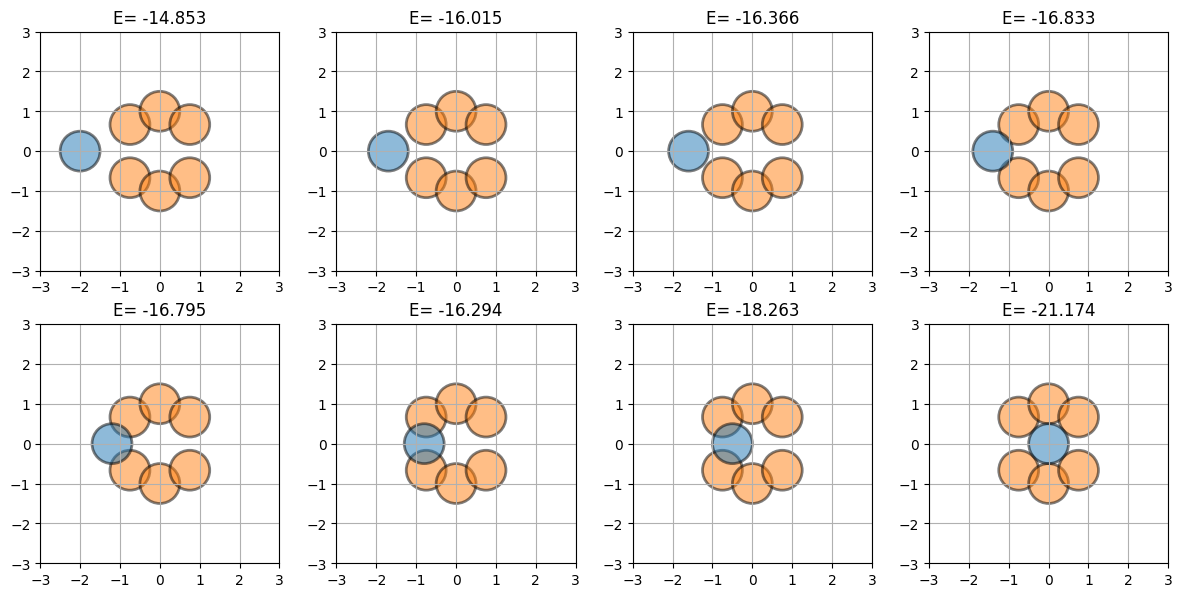

In [117]:
# static_pos = [[-3/4, 3/4], [0, 1], [3/4, 3/4], [-3/4, -3/4], [0, -1], [3/4, -3/4]]
static_pos = [[-3/4, 2/3], [0, 1], [3/4, 2/3], [-3/4, -2/3], [0, -1], [3/4, -2/3]]
static = [True]*6+[False]

morse = Morse()
x = [-2.0,-1.7,-1.6,-1.4,-1.2,-0.8,-0.5,0.0]
E = []
fig, axes = plt.subplots(2,4,figsize=(12,6))
for ax, xi in zip(axes.flatten(),x):
    pos = static_pos.copy()
    pos.append([xi,0])
    atomic_cluster = AtomicCluster(morse, pos=pos, static=static)
    atomic_cluster.draw(ax)
    E.append(atomic_cluster.potential_energy)
    ax.set_xlim(-3,3)
    ax.set_ylim(-3,3)
    ax.grid()
    ax.set_aspect('equal')
    ax.set_xticks([-3,-2,-1,0,1,2,3])
fig.tight_layout()

Text(0, 0.5, 'Energy')

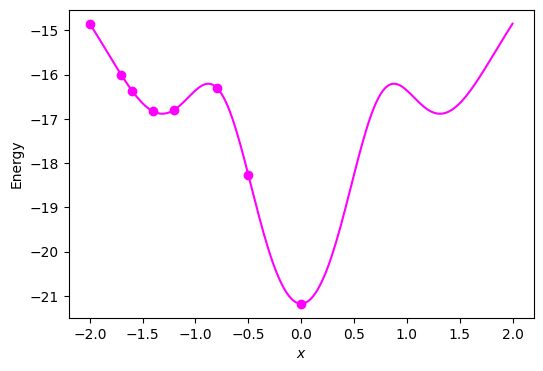

In [118]:
x_lin = np.linspace(-2,2,200)
E_lin = []
for xi in x_lin:
    pos = static_pos.copy()
    pos.append([xi,0])
    atomic_cluster = AtomicCluster(morse, pos=pos, static=static)
    E_lin.append(atomic_cluster.potential_energy)


fig, ax = plt.subplots(1,1,figsize=(6,4))
ax.plot(x_lin, E_lin, c='magenta')
ax.scatter(x, E, c='magenta')
ax.set_xlabel(r'$x$')
ax.set_ylabel('Energy')
# fig.tight_layout()

### Task 2: establish three representations of the data

Construct three datasets with the same target energies, but different representations of the input configurations

In [ ]:
from week07 import DescriptorBase
from scipy.spatial.distance import pdist, squareform

dataset_x = list(zip(x, E))

class ManyBinsDescriptor(DescriptorBase):

    centers = np.arange(0, 7.5, 0.5)
    ylim = [0, 25]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist, _ = np.histogram(dist_vector, self.edges)
        return hist.tolist()   # returns the bin counts
    
mbd = ManyBinsDescriptor()
dataset_mbd = []
for xi, Ei in zip(x, E):
    pos = static_pos.copy()
    pos.append([xi,0])
    dataset_mbd.append([mbd(pos),Ei])

class CoulombMatrixSpectrumDescriptor():
    def __call__(self, pos):
        # make interatomic distance matrix
        # squareform simply turns the vector of interatomic 
        # distances to a matrix, distances between neighbors.
        dist_matrix = squareform(pdist(pos))
        # make the diagonal 1 before inverse
        np.fill_diagonal(dist_matrix, 1.0)
        coulomb_matrix = 1.0 / dist_matrix
        # get eigenvalues (the coulomb matrix spectrum)
        eigenvalues, eigenvectors = np.linalg.eigh(coulomb_matrix)
        idx = np.argsort(eigenvalues)[::-1]   # Returns the indices that sorts the array in reverse order (high to low)
        eigenvalues = eigenvalues[idx]
        return eigenvalues.tolist()

cmsd = CoulombMatrixSpectrumDescriptor()

dataset_cmsd = []
for xi, Ei in zip(x, E):
    pos = static_pos.copy()
    pos.append([xi,0])
    dataset_cmsd.append([cmsd(pos),Ei])

print(dataset_x[0],'\n', dataset_mbd[0], '\n', dataset_cmsd[0])

(-2.0, np.float64(-14.853230624384478)) 
 [[0, 0, 4, 6, 9, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0], np.float64(-14.853230624384478)] 
 [[5.166304015118963, 1.4093819115520827, 0.9566815314642384, 0.2829201171734733, 0.08160621245577315, -0.4059056637566754, -0.4909881240078558], np.float64(-14.853230624384478)]


$(x_i, E_i)$ contains 1 feature, namely the $x_i$ coordinate of the free atom.

$(f_{PairDistances}(x_i), E_i)$ contains 14 features, the interatomic distances ranging from 0 to 7 with step of 0.5.

$(f_{CoulombMatrixSpectrum}(x_i), E_i)$ contains 7 features: 7 atoms with 7x7 pairwise distance matrix gives an inverse matrix of size 7x7 with 7 eigenvalues.

Changing one (static) atomic coordinate can affect the energies $E_i$ of all components. For the PairDistances and CoulombMatrixSpectrum, it also affects the features.

### Task 3: fit without an atomic descriptor

Use the first dataset to make a kernel ridge regression fit with the Gaussian kernel. In this model,
the prediction is based only on the scalar coordinate 𝑥.

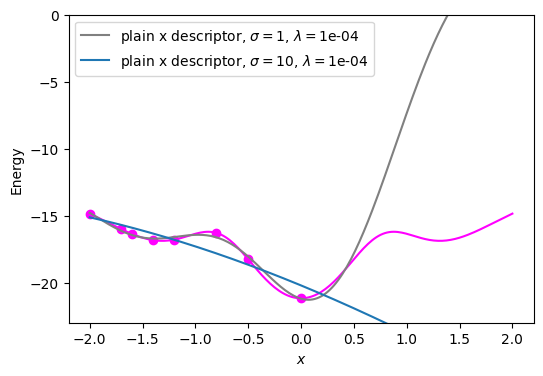

In [132]:
class GaussianKernel1D():
    def __init__(self, sigma):
        self.sigma = sigma

    def __call__(self, x1, x2):
        x1 = np.atleast_1d(x1)  # ensures that the next part of the code works as intented
        x2 = np.atleast_1d(x2)  # i.e. also for integer inputs
        return np.exp(-(x1[:, None]-x2[None, :])**2/(2*self.sigma**2))  # numpy broadcasting

class KernelRidgeRegression():
    def __init__(self, kernel, log10l=-1):
        self.kernel = kernel
        self.l = 10**log10l

    def _K(self, x1, x2):
        return self.kernel(x1,x2)

    def fit(self, X, y):
        self.X_train = X
        K = self._K(X, X)
        self.alpha = np.linalg.inv(K + self.l*np.identity(K.shape[1])) @ y

    def predict(self, X):
        K = self._K(X, self.X_train)
        y_pred = K @ self.alpha
        return y_pred

    def plot(self, ax, X, c='C0', label='Gaussian kernel'):
        ax.plot(X, self.predict(X), c=c, label=label+r', $\sigma=$'+f'{self.kernel.sigma}, '+r'$\lambda=$'+f'{self.l:.0e}')
        ax.grid()
        ax.legend()

fig, ax = plt.subplots(1,1,figsize=(6,4))
ax.plot(x_lin, E_lin, c='magenta')
ax.scatter(x, E, c='magenta')
ax.set_xlabel(r'$x$')
ax.set_ylabel('Energy')
ax.set_ylim(-23,0)

for sigma, c in zip([1, 10], ['grey', 'C0']):
    kernel = GaussianKernel1D(sigma=sigma)
    krr = KernelRidgeRegression(kernel=kernel, log10l=-4)
    x_fit, E_fit = zip(*dataset_x)
    krr.fit(x_fit, E_fit)
    krr.plot(ax, x_lin, c=c, label='plain x descriptor')

With small $\sigma$, the kernel decrease rapidly as the distance from a training point increases. Predictions can change rapidly between data points. Outside the range of training points, the extrapolation tends toward zero, because all kernel values become small.

With large $\sigma$, the kernel decrease more slowly as the distance from a training point increases. Predictions change slower between data points, which can easily be seen in the interpolation for $\sigma=10$. The larger $\sigma$ includes information from more points, allowing for a more smoothed prediction. We see this as a predicted straight line, so the local features (e.g. local minima) can be missed. Outside the sampled region, the extrapolation may go slower towards zero.

### Task 4: fit using the pair-distance descriptor

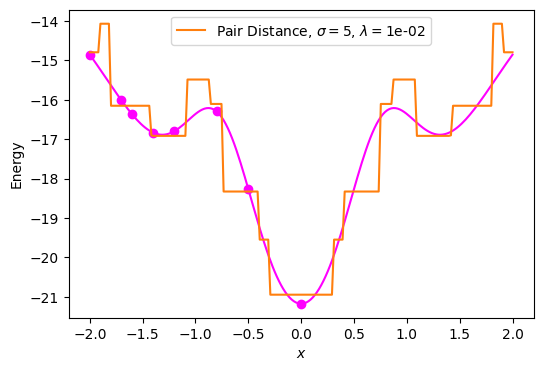

In [136]:
class GaussianKernelXD():
    '''Should work for samples with more than one feature'''
    def __init__(self, sigma):
        self.sigma = sigma

    def __call__(self, x1, x2):
        x1 = np.asarray(x1)   # ensure array type, not tuple etc.
        x2 = np.asarray(x2)
        # compute sum of square distances over all features
        sqdist = ((x1[:, None] - x2[None, :])**2).sum(axis=-1)
        return np.exp(-sqdist/(2*self.sigma**2))

class KRRManyD(KernelRidgeRegression):
    '''This gives access to predicting on features that are not 1D'''
    def plot(self, ax, xs, X, c='C0', label='Gaussian kernel'):
        ax.plot(xs, self.predict(X), c=c, label=label+r', $\sigma=$'+f'{self.kernel.sigma}, '+r'$\lambda=$'+f'{self.l:.0e}')
        # ax.grid()
        ax.legend()

fig, ax = plt.subplots(1,1,figsize=(6,4))
ax.plot(x_lin, E_lin, c='magenta')
ax.scatter(x, E, c='magenta')
ax.set_xlabel(r'$x$')
ax.set_ylabel('Energy')

kernel = GaussianKernelXD(sigma=5)
krr = KRRManyD(kernel=kernel, log10l=-2)
x_fit, E_fit = zip(*dataset_mbd)
krr.fit(x_fit, E_fit)
# we need to make the descriptor for all x-values on the dense grid
x_mbd = []
for xi in x_lin:
    pos = static_pos.copy()
    pos.append([xi,0])
    x_mbd.append(mbd(pos))
# we provide both the dense grid for plotting and its corrosponding descriptors
krr.plot(ax, x_lin, x_mbd, c='C1', label='Pair Distance')

The Gaussian kernel now evaluates Euclidean distances in the 14-dimensional descriptor space
rather than distances along the original 𝑥-coordinate. Discuss how this changes the similarities
between configurations. Pay particular attention to any consequence of using a histogram descriptor, for which the components change discretely when an interatomic distance crosses a bin boundary.

<br>

*Answer*

In contrast to the original descriptor, the kernel no longer compares the physical distance between atomic configurations, i.e. the distance between $x_i$ and $x_j$. Instead, it compares the 14-bin pair-distance histograms and how much they differ from each other. Two atomic configurations that are physically alike may be significantly different in their pair-distance histograms. This is especially signifant when the components change in a discreticed space as opposed to a continous space. When crossing a bin boundary, the change can be dramatic for the histogram descriptor as opposed to the original or a continous space descriptor.

### Task 5: fit using the Coulomb-matrix-spectrum descriptor

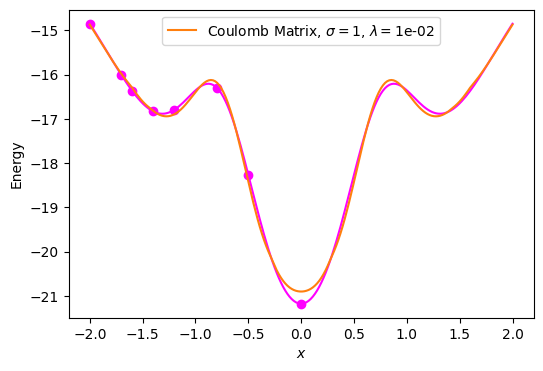

In [137]:
fig, ax = plt.subplots(1,1,figsize=(6,4))
ax.plot(x_lin, E_lin, c='magenta')
ax.scatter(x, E, c='magenta')
ax.set_xlabel(r'$x$')
ax.set_ylabel('Energy')

kernel = GaussianKernelXD(sigma=1)
krr = KRRManyD(kernel=kernel, log10l=-2)
x_fit, E_fit = zip(*dataset_cmsd)
krr.fit(x_fit, E_fit)
# we need to make the descriptor for all x-values on the dense grid
x_cmsd = []
for xi in x_lin:
    pos = static_pos.copy()
    pos.append([xi,0])
    x_cmsd.append(cmsd(pos))
# we provide both the dense grid for plotting and its corrosponding descriptors
krr.plot(ax, x_lin, x_cmsd, c='C1', label='Coulomb Matrix')

Compare this fit with those based on the scalar coordinate and the pair-distance descriptor. Which representation
gives the most useful notion of similarity between the atomic configurations in this example?
Discuss the smoothness, interpolation, and extrapolation of the three models, and explain why a
higher-dimensional descriptor is not automatically a better descriptor.

<br>

*Answer*

The Coulomb-matrix-spectrum is the best representation for the atomic configurations in this example, with good interpolation and great extrapolation. Same is true for the pdist descriptor, but it lacks smoothness to get accurate predictions. The plain $x$ descriptor also gives good interpolation, but bad extrapolation, which makes it a poor choice when you have few data points.

The highest dimensional descriptor, the pdist with 14 features, did not result in the best representation, thus indicating that a higher-dimensional descriptor is not automatically a better descriptor. Many of these dimensions may provide little to no useful information about the configurations, where methods of dimensionality reduction could be used. Increasing the number of bins in the pdist descriptor may give much better results, but a very good representation can be found with just a fraction of the features with eg. the Coulomb matrix.


